# Archaic Gene Flow and Shared Alleles

The Manhattan surface describes where ancestry connects populations.
Can present-day and ancient DNA reveal whether populations reconnected
after a split? First compare pair genealogies under three histories.
Then use ABBA–BABA and the $f_4$ ratio to answer two questions about
Neanderthal ancestry.

In [1]:
library(hpgR)
options(repr.plot.width = 10, repr.plot.height = 4.5,
        repr.plot.pointsize = 14, warn = 1)
drawFigure <- function(name, draw, width = 10, height = 4.5) {
    options(repr.plot.width = width, repr.plot.height = height)
    directory <- Sys.getenv("P8149_FIGURE_DIR")
    if (nzchar(directory)) {
        dir.create(directory, recursive = TRUE, showWarnings = FALSE)
        pdf(file.path(directory, paste0(name, ".pdf")), width = width, height = height)
        tryCatch(draw(legend_spacing = 1), finally = dev.off())
    }
    if ("IRkernel" %in% loadedNamespaces()) {
        par(bg = "white")
        draw(legend_spacing = 2.1)
    }
    invisible(NULL)
}

blue <- "#1D4F91"
red <- "#D14124"
gray <- "#626A73"

## Similar mean ancestor times, different histories

Sample one copy in each of two daughter populations ($N_e=100$ each).
Backward in time, each lineage switches parental populations with
probability $m_t$. Two lineages in the same parental population
coalesce with probability $1/(2N_e)$. After the split both enter the
ancestral population ($N_e=300$).

| History | Split, generations ago | Migration |
| --- | ---: | --- |
| Isolation | 160 | 0 |
| Continuous exchange | 250 | about 0.000746 per generation |
| Secondary contact | 250 | one pulse of about 0.105, 35 generations ago |

The rates were set using the survival recursion so the mean cross-population
ancestor time is 760 generations under all three histories.
For each simulated region, let $T_2$ be its ancestor time and $M$ the number
of sequence differences across $L$ bases. Under infinite sites,

$$M\mid T_2\sim\operatorname{Poisson}(2\mu L T_2).$$

Use $\mu L=0.002$ and 20,000 independent regions per history. The expected
count is $2(0.002)(760)=3.04$ in each model. Compare the fractions of
regions with zero differences.

In [2]:
daughterCopies <- 200L
ancestorCopies <- 600L
recentSplit <- 160L
oldSplit <- 250L
contact <- 35L

targetTime <- recentSplit + ancestorCopies
recurrentRate <- 0.00074624335494818288
pulseRate <- 0.10458868507954684
schedules <- list(
    Isolation = numeric(recentSplit),
    Continuous = rep(recurrentRate, oldSplit),
    "Secondary contact" = replace(numeric(oldSplit), contact, pulseRate)
)
expected <- setNames(rep(targetTime, length(schedules)), names(schedules))

set.seed(8151)
regions <- 20000L
crossTimes <- vapply(schedules, function(m) {
    simulateCrossPopulationTimes(regions, m, daughterCopies, ancestorCopies)
}, numeric(regions))
stopifnot(all(crossTimes[, "Isolation"] > recentSplit),
          all(abs(colMeans(crossTimes) - expected) <
              4 * apply(crossTimes, 2, sd) / sqrt(regions)))
clock <- 0.002 # mu * L for each region, per branch-generation
differences <- vapply(seq_along(schedules), function(j) {
    rpois(regions, 2 * clock * crossTimes[, j])
}, numeric(regions))
colors <- c(blue, "#2E7D32", red)

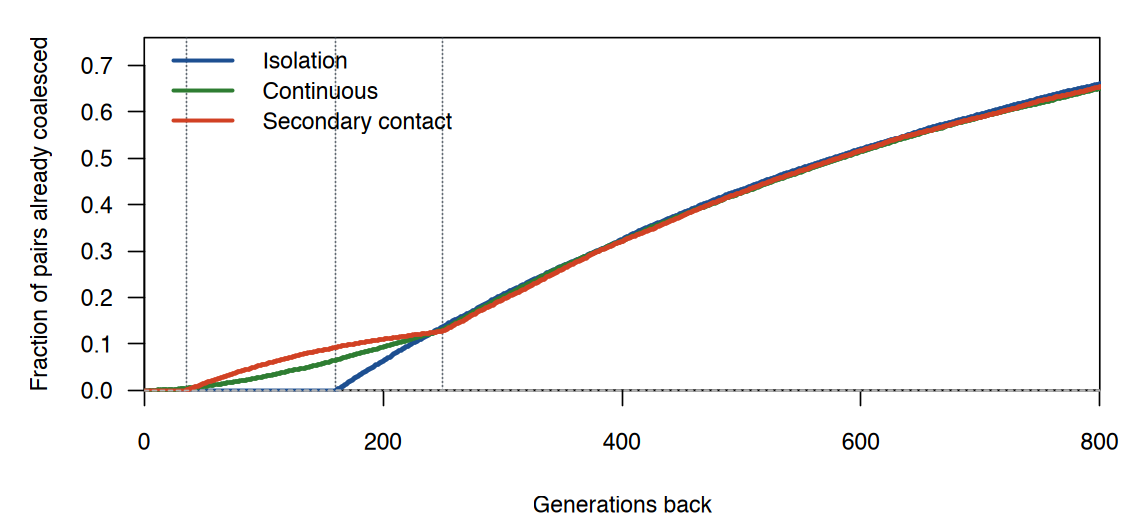

In [3]:
drawFigure("migration_cross_population_ancestry", function(legend_spacing) {
    par(mar = c(4.2, 4.6, 1.2, 0.9), las = 1, cex = 1.12)
    plot(NA, xlim = c(0, 800), ylim = c(0, 0.76), xaxs = "i", yaxs = "i",
         xlab = "Generations back", ylab = "Fraction of pairs already coalesced")
    abline(v = c(contact, recentSplit, oldSplit), lty = 3, col = gray)
    for (j in seq_along(schedules)) {
        lines(ecdf(crossTimes[, j]), do.points = FALSE, verticals = TRUE,
              lwd = 2.4, col = colors[j])
    }
    legend("topleft", names(schedules), col = colors, lty = 1, lwd = 2.4,
           bty = "n", y.intersp = legend_spacing)
}, width = 9.4, height = 4.35)

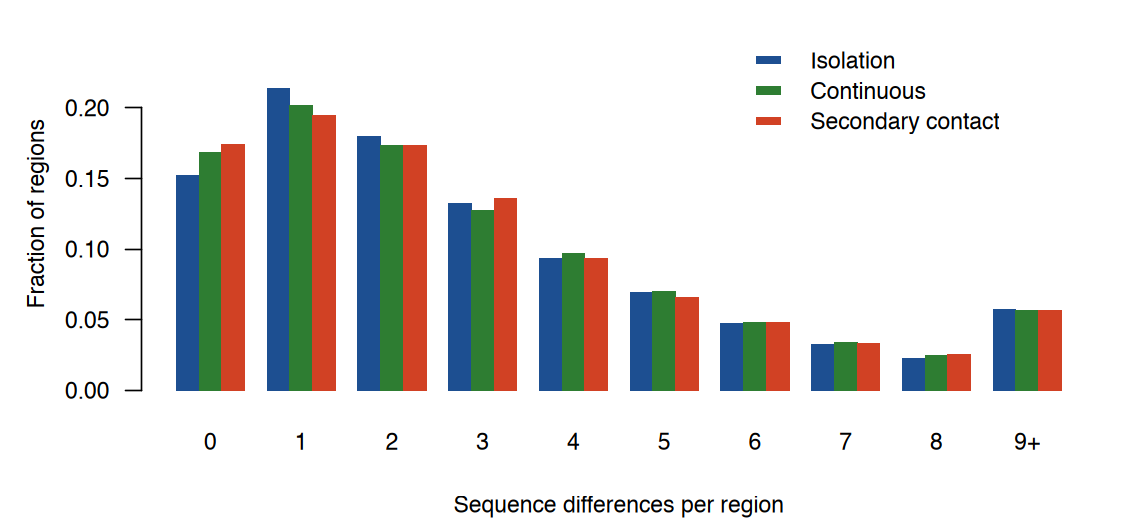

In [4]:
drawFigure("migration_cross_population_differences", function(legend_spacing) {
    par(mar = c(4.2, 4.5, 1.2, 1), las = 1, cex = 1.12)
    counts <- sapply(seq_along(schedules), function(j) {
        tabulate(pmin(differences[, j], 9L) + 1L, nbins = 10L) / regions
    })
    barplot(t(counts), beside = TRUE, names.arg = c(0:8, "9+"),
            col = colors, border = NA, ylim = c(0, max(counts) * 1.17),
            xlab = "Sequence differences per region", ylab = "Fraction of regions")
    legend("topright", names(schedules), fill = colors, border = NA,
           bty = "n", y.intersp = legend_spacing)
}, width = 9.4, height = 4.35)

In [5]:
round(rbind(
    mean_ancestor_generations = colMeans(crossTimes),
    mean_differences = colMeans(differences),
    fraction_zero_differences = colMeans(differences == 0)
), 3)

,Isolation,Continuous,Secondary contact
mean_ancestor_generations,757.955,761.791,754.526
mean_differences,3.039,3.036,3.016
fraction_zero_differences,0.152,0.168,0.174


## ABBA and BABA after a split and a pulse

Order the sequences as $(P_1,P_2,P_3,O)$, where $O$ is the outgroup
used to identify the ancestral allele $A$. A mutation on the
$(P_2,P_3)$ internal branch produces ABBA. A mutation on the
$(P_1,P_3)$ branch produces BABA. Given branch length $b$ in generations,
draw the mutation count from $\operatorname{Poisson}(\mu L b)$.

The population tree is $((P_1,P_2),P_3)$. In a randomly mating common
ancestor, incomplete lineage sorting gives the two discordant branches
equal expected lengths. A pulse from $P_3$ into $P_2$ gives that pair an
earlier chance to coalesce and increases the expected ABBA count.

The splits occur 1,000 and 1,600 generations ago. All populations have
$N_e=1{,}000$. Compare isolation with a pulse 300 generations ago supplying
20% of $P_2$ ancestry. Use $\mu L=0.0002$ and 48 panels of 4,000
independent loci. For the simulated counts, compute the same contrast
used in the lecture,

$$D=\frac{n_{\mathrm{ABBA}}-n_{\mathrm{BABA}}}
          {n_{\mathrm{ABBA}}+n_{\mathrm{BABA}}}.$$

Positive $D$ means more sharing of derived alleles between $P_2$ and $P_3$.
A structured ancestor can also produce asymmetry. The calculation tests
the symmetry predicted by the simple split model.

In [6]:
split12 <- 1000L
split123 <- 1600L
pulseTime <- 300L
Ne <- 1000L
muL <- 0.0002
loci <- 4000L
alpha <- c(0, 0.20)
panels <- 48L
set.seed(814911)
patterns <- vapply(alpha, function(a) {
    replicate(panels, simulateAbbaBaba(loci, a, Ne, split12, split123, pulseTime, muL))
}, matrix(0, nrow = 2, ncol = panels))

# Each pair gets the same expected branch length when all three reach the
# ancestral population. The early merger window adds its full length in
# expectation to the eligible pair (including the wait for the final merger).
deep <- (2 * Ne / 3) * (
    (1 - alpha) * exp(-(split123 - split12) / (2 * Ne)) +
    alpha * exp(-(split123 - pulseTime) / (2 * Ne)))
expected_counts <- loci * muL * rbind(deep + alpha * (split123 - pulseTime), deep)
patternMean <- apply(patterns, c(1, 3), mean)
patternSE <- apply(patterns, c(1, 3), sd) / sqrt(panels)
stopifnot(all(abs(patternMean - expected_counts) < 4 * patternSE))

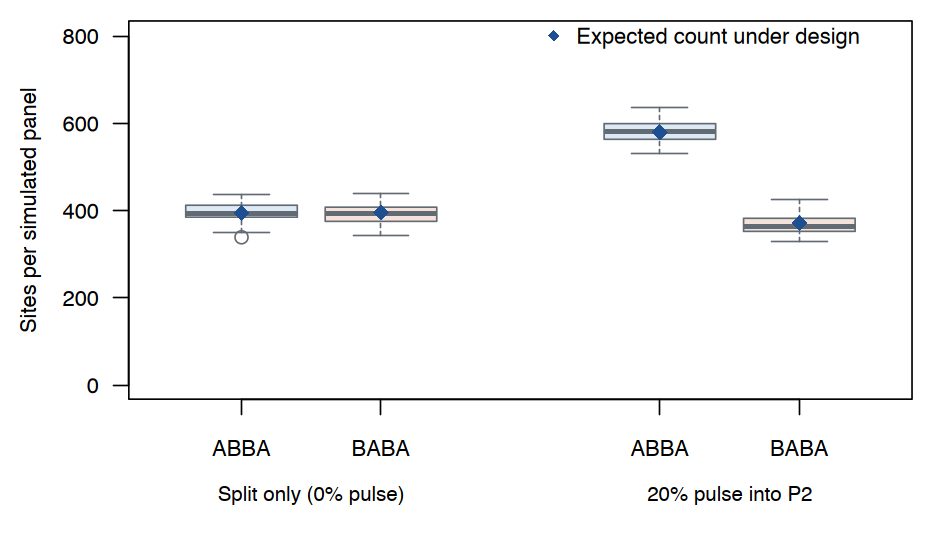

In [7]:
drawFigure("abba_baba_simulation", function(legend_spacing) {
    par(mar = c(4.9, 4.3, 0.7, 0.8), las = 1, cex = 1.07)
    boxplot(patterns[1, , 1], patterns[2, , 1], patterns[1, , 2],
            patterns[2, , 2], at = c(1, 2, 4, 5), xaxt = "n",
            xlim = c(0.4, 5.6), ylim = c(0, max(patterns) * 1.26),
            col = rep(c("#DDE9F5", "#F5E3DB"), 2), border = gray,
            ylab = "Sites per simulated panel")
    axis(1, at = c(1, 2, 4, 5), labels = rep(c("ABBA", "BABA"), 2))
    mtext(c("Split only (0% pulse)", "20% pulse into P2"), side = 1,
          at = c(1.5, 4.5), line = 2.5, font = 2)
    points(c(1, 2, 4, 5), as.vector(expected_counts), pch = 18, cex = 1.45, col = blue)
    legend("topright", "Expected count under design", pch = 18, col = blue, bty = "n")
}, width = 7.8, height = 4.55)

In [8]:
design_names <- c("Split only", "20% pulse")
colnames(patternMean) <- colnames(expected_counts) <- design_names
round(patternMean, 1)

informative <- patterns[1, , ] + patterns[2, , ]
stopifnot(all(informative > 0))
D <- (patterns[1, , ] - patterns[2, , ]) / informative
expected_D <- (expected_counts[1, ] - expected_counts[2, ]) /
    colSums(expected_counts)
round(rbind(mean_panel_D = colMeans(D), ratio_of_expected_counts = expected_D), 3)

,Split only,20% pulse
ABBA,396.5,579.4
BABA,391.6,367.5


,Split only,20% pulse
mean_panel_D,0.006,0.224
ratio_of_expected_counts,0.000,0.219


## Neanderthal allele sharing across human samples

These six estimates are the selected contrasts in the lecture from
Green et al., Table 4. Neanderthal and chimpanzee stay fixed. The bars
show one standard error in either direction. Larger positive values for
African–non-African pairs show an excess of shared derived variants with
the non-African sample.
[Green et al. (2010), Table 4](https://pmc.ncbi.nlm.nih.gov/articles/PMC5100745/#T4).

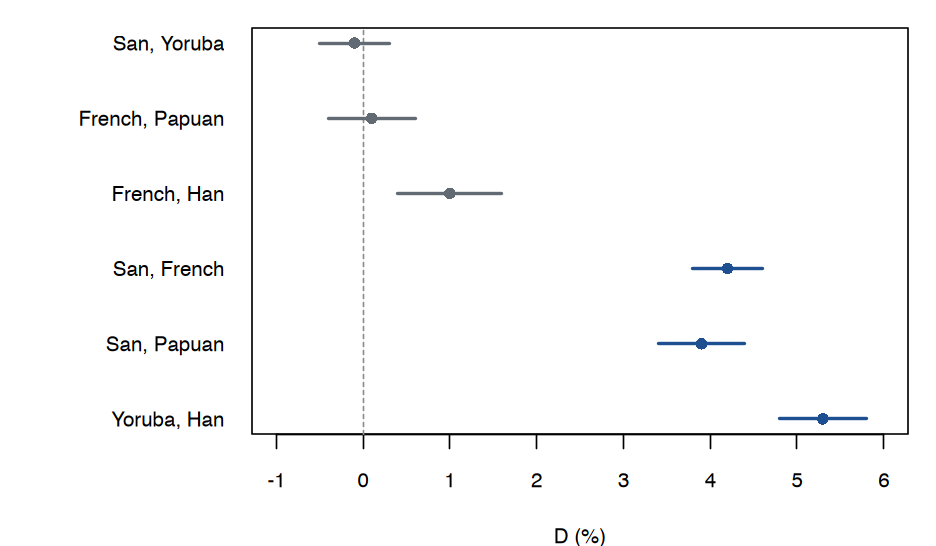

In [9]:
contrasts <- data.frame(
    pair = c("San, Yoruba", "French, Papuan", "French, Han",
             "San, French", "San, Papuan", "Yoruba, Han"),
    D_percent = c(-0.1, 0.1, 1.0, 4.2, 3.9, 5.3),
    SE_percent = c(0.4, 0.5, 0.6, 0.4, 0.5, 0.5)
)
y <- rev(seq_len(nrow(contrasts)))
ink <- c(rep(gray, 3), rep(blue, 3))
saved_par <- par(mar = c(4, 9, 1, 1), bg = "white")
with(contrasts, {
    plot(D_percent, y, type = "n", xlim = c(-1, 6), yaxt = "n",
         xlab = "D (%)", ylab = "")
    axis(2, at = y, labels = pair, las = 1, tick = FALSE)
    abline(v = 0, lty = 2, col = "grey55")
    segments(D_percent - SE_percent, y, D_percent + SE_percent, y, col = ink, lwd = 2)
    points(D_percent, y, col = ink, pch = 16)
})
par(saved_par)

## Estimate a mixture fraction with an $f_4$ ratio

Let $X$ receive fraction $q$ from $B'$ and $1-q$ from $C'$. The sampled
populations $B$ and $C$ are relatives of those sources. The graph gives
$A$ the same ancestral drift with $B$ and $B'$. Relative to $(A,O)$,
the $C'$–$C$ contrast has zero expected shared drift.

At each locus, multiply the allele-frequency differences
$(p_A-p_O)(p_X-p_C)$ and average them across loci to estimate
$f_4(A,O;X,C)$. The graph gives
$f_4(A,O;X,C)=q f_4(A,O;B,C)$, so the estimator divides the two
sample contrasts when the denominator is nonzero.

Simulate Wright–Fisher drift along this graph with 300 copies per edge.
Use 48 panels of 20,000 independent SNPs and generating fractions
0%, 20%, and 50%. The plot marks the generating values in red.

In [10]:
set.seed(8150)
truth <- c(0, 0.20, 0.50)
ratioSites <- 20000L
ratios <- replicate(panels, {
    # Simulate independent loci along the population graph.
    copies <- 300L
    root <- runif(ratioSites, .1, .9)
    outgroup <- rbinom(ratioSites, copies, root) / copies
    ingroup <- rbinom(ratioSites, copies, root) / copies
    archaic <- rbinom(ratioSites, copies, ingroup) / copies
    modern <- rbinom(ratioSites, copies, ingroup) / copies
    related <- rbinom(ratioSites, copies, archaic) / copies
    A <- rbinom(ratioSites, copies, archaic) / copies
    B <- rbinom(ratioSites, copies, related) / copies
    Bsource <- rbinom(ratioSites, copies, related) / copies
    C <- rbinom(ratioSites, copies, modern) / copies
    Csource <- rbinom(ratioSites, copies, modern) / copies
    denominator <- frequencyF4(A, outgroup, B, C)
    vapply(truth, function(q) {
        X <- rbinom(ratioSites, copies, q * Bsource + (1 - q) * Csource) / copies
        frequencyF4(A, outgroup, X, C) / denominator
    }, numeric(1L))
})
ratioMean <- rowMeans(ratios)
ratioSE <- apply(ratios, 1L, sd) / sqrt(panels)
stopifnot(all(abs(ratioMean - truth) < 4 * ratioSE))

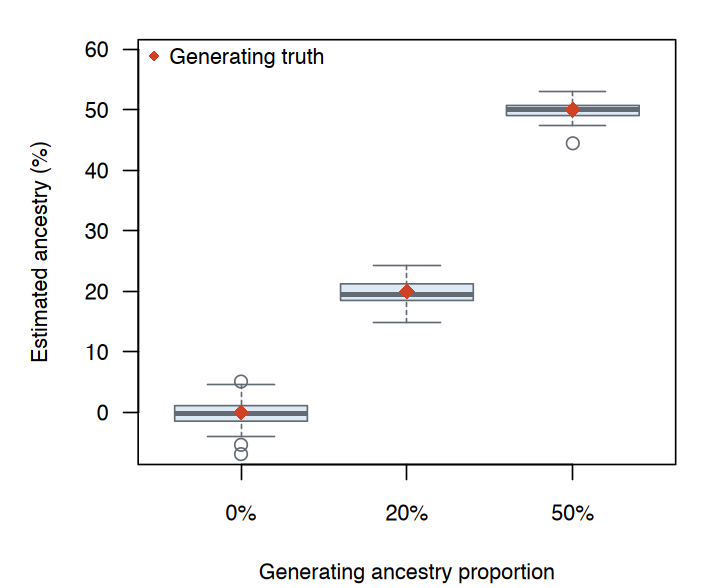

In [11]:
drawFigure("f4_ancestry_ratio_simulation", function(legend_spacing) {
    par(mar = c(4.2, 4.7, 1.35, 1.1), las = 1, cex = 1.05)
    boxplot(as.data.frame(t(100 * ratios)), names = paste0(100 * truth, "%"),
            col = "#DDE9F5", border = gray, ylim = c(-6, 59),
            xlab = "Generating ancestry proportion", ylab = "Estimated ancestry (%)")
    points(seq_along(truth), 100 * truth, pch = 18, cex = 1.5, col = red)
    legend("topleft", "Generating truth", pch = 18, col = red, bty = "n")
}, width = 5.9, height = 4.9)

For the empirical ratio, Patterson et al. used Denisovan and chimpanzee
for $(A,O)$, and Neanderthal, French, and Yoruba for $(B,X,C)$.
The estimated Neanderthal contribution to the French sample was
**2.2% ± 0.7%** (estimate ± one standard error) under this graph.
[Patterson et al. (2012), Fig. 4 and Eqs. 4–5](https://academic.oup.com/genetics/article/192/3/1065/5935193).

## One pulse or repeated migration

Start with zero donor ancestry in a recipient. A fraction $m$ comes from
the donor each generation, so $q_{t+1}=(1-m)q_t+m$.
Choose $m$ so that ten generations reach the same ancestry proportion as a
single 20% pulse. The final proportion gives the same answer for both
histories; linked segments carry information about when ancestry entered.

In [12]:
target <- 0.20
duration <- 10L
m <- 1 - (1 - target)^(1 / duration)
data.frame(pulse = target, gradual = 1 - (1 - m)^duration,
           migration_per_generation = m)
stopifnot(isTRUE(all.equal(1 - (1 - m)^duration, target)))

pulse,gradual,migration_per_generation
<dbl>,<dbl>,<dbl>
0.2,0.2,0.02206723


Next: [Local Genealogies and Introgressed Segments](P8149_Lecture_10_Ancestral_Graphs.ipynb).